<a href="https://colab.research.google.com/github/JSAIRAM392/CCPP-Energy-Prediction/blob/main/CCPP_Energy_Output_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Combined Cycle Power Plant Energy Output Prediction
## Performance Analysis and Comparison of Regression Models

**Guide:** Ms.Sameera D

**Batch:** 23

**Authors:**

   . J Sairam(24911A66F0)

   . J Manikanta(24911A66J8)

   . G Sikinder(24911A66E6)

**Problem statement:** Predict the net hourly electrical power output (PE, in MW) of a Combined Cycle Power Plant using ambient temperature (AT), exhaust vacuum (V), ambient pressure (AP), and relative humidity (RH).

**Dataset:** UCI Combined Cycle Power Plant dataset — 9,568 observations collected from 2006–2011.

**Algorithms:** Linear Regression, Random Forest Regressor, and Gradient Boosting Regressor.

**Evaluation metrics:** MAE, RMSE, and R² score.

### Objectives
1. Load and understand the CCPP dataset.
2. Check data quality and explore feature relationships.
3. Split the data into training and testing sets.
4. Train three regression models.
5. Compare model performance and identify the best model.
6. Visualize actual vs. predicted output and feature importance.

### Project steps
1. Import libraries
2. Load dataset
3. Explore and prepare data
4. Visualize correlations
5. Split data
6. Train models
7. Evaluate and compare models
8. Visualize results and save the best model

> Dataset columns expected: `AT`, `V`, `AP`, `RH`, and target `PE`. The dataset description says there are no missing values.

## 1. Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

## 2. Load the dataset

Upload `Folds5x2_pp.xlsx` to the notebook session, or use the optional UCI download method below.

In [ ]:
# Option A: Upload the official Excel file to the current working directory.
# Expected file: Folds5x2_pp.xlsx
try:
    df = pd.read_excel("Folds5x2_pp.xlsx")
except FileNotFoundError:
    # Option B: Download via the UCI Machine Learning Repository package.
    try:
        from ucimlrepo import fetch_ucirepo
    except ModuleNotFoundError:
        print("ucimlrepo package not found. Installing it now...")
        import subprocess
        import sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ucimlrepo"])
        from ucimlrepo import fetch_ucirepo

    ccpp = fetch_ucirepo(id=294)
    X_uci = ccpp.data.features
    y_uci = ccpp.data.targets
    df = X_uci.copy()
    target_name = y_uci.columns[0]
    df[target_name] = y_uci[target_name]

# Normalize column names and handle the common target alias.
df.columns = [str(c).strip() for c in df.columns]
if "EP" in df.columns and "PE" not in df.columns:
    df = df.rename(columns={"EP": "PE"})

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## 3. Explore and validate the data

In [ ]:
print("Column names:", list(df.columns))
display(df.describe().T)
print("\\nMissing values per column:")
display(df.isnull().sum())

Column names: ['AT', 'V', 'AP', 'RH', 'PE']


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


\nMissing values per column:


,0
AT,0
V,0
AP,0
RH,0
PE,0


In [ ]:
required_columns = ["AT", "V", "AP", "RH", "PE"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

df = df[required_columns].copy()
df = df.dropna()
print("Shape after removing missing rows:", df.shape)

Shape after removing missing rows: (9568, 5)


## 4. Exploratory data analysis

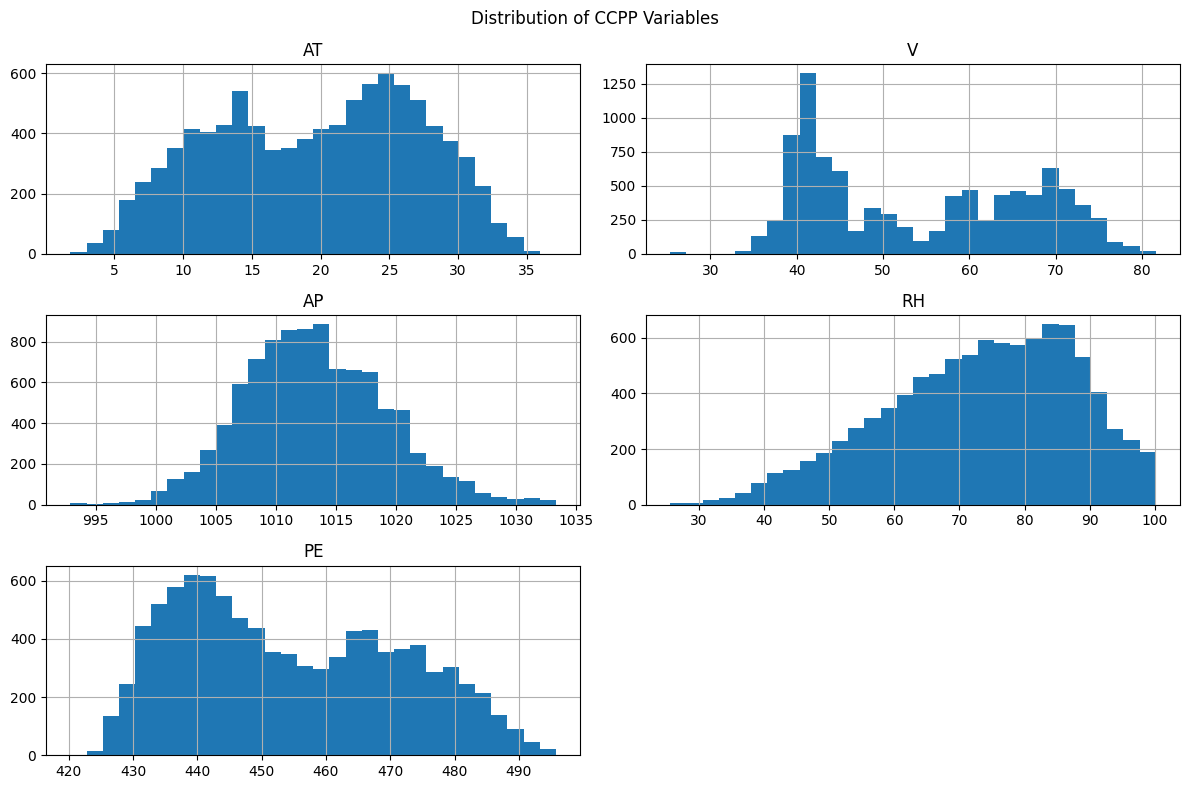

In [ ]:
df[["AT", "V", "AP", "RH", "PE"]].hist(figsize=(12, 8), bins=30)
plt.suptitle("Distribution of CCPP Variables")
plt.tight_layout()
plt.show()

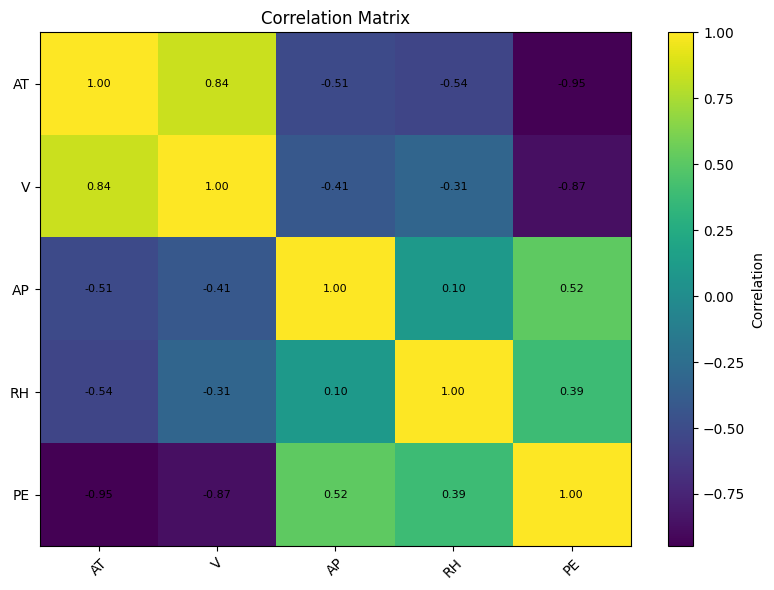

In [ ]:
plt.figure(figsize=(8, 6))
plt.imshow(df.corr(numeric_only=True), aspect="auto")
plt.xticks(range(len(df.columns)), df.columns, rotation=45)
plt.yticks(range(len(df.columns)), df.columns)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")
for i in range(len(df.columns)):
    for j in range(len(df.columns)):
        plt.text(j, i, f"{df.corr(numeric_only=True).iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Prepare training and testing data

Use an 80/20 split. A fixed random state makes the experiment reproducible.

In [ ]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 7654
Testing records: 1914


## 6. Train regression models

In [ ]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42
    )
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE (MW)": mean_absolute_error(y_test, pred),
        "RMSE (MW)": np.sqrt(mean_squared_error(y_test, pred)),
        "R² Score": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).sort_values("RMSE (MW)")
display(results_df.round(4))

,Model,MAE (MW),RMSE (MW),R² Score
1,Random Forest,2.3147,3.2310,0.9640
2,Gradient Boosting,2.9575,3.8380,0.9492
0,Linear Regression,3.5959,4.5026,0.9301


## 7. Compare model performance

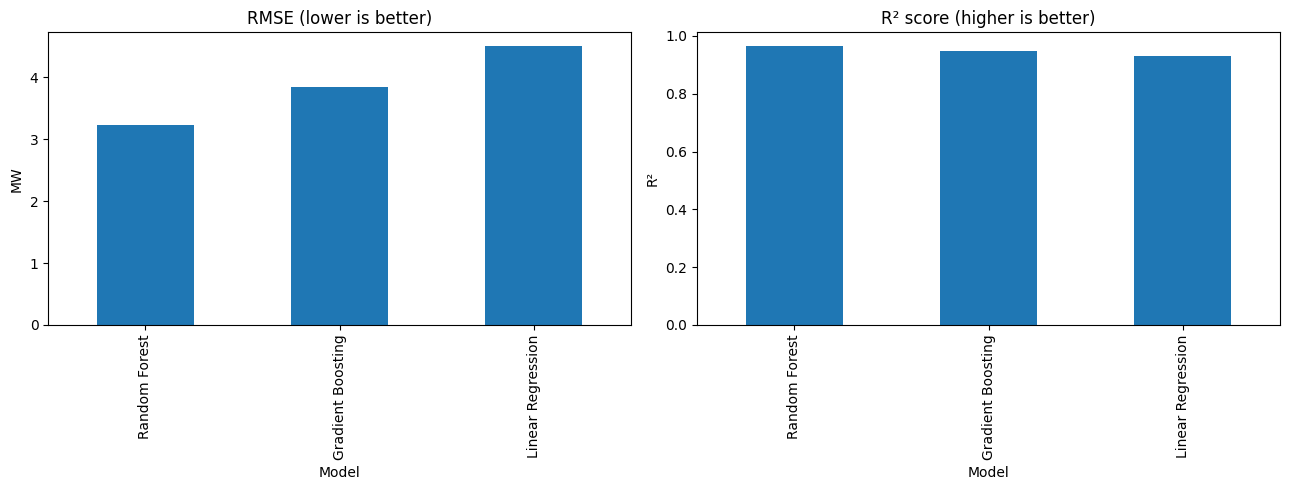

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
results_plot = results_df.set_index("Model")
results_plot["RMSE (MW)"].plot(kind="bar", ax=axes[0], title="RMSE (lower is better)")
results_plot["R² Score"].plot(kind="bar", ax=axes[1], title="R² score (higher is better)")
axes[0].set_ylabel("MW")
axes[1].set_ylabel("R²")
plt.tight_layout()
plt.show()

## 8. Actual vs. predicted values for the best model

Best model by RMSE: Random Forest
MAE:  2.315 MW
RMSE: 3.231 MW
R²:   0.9640


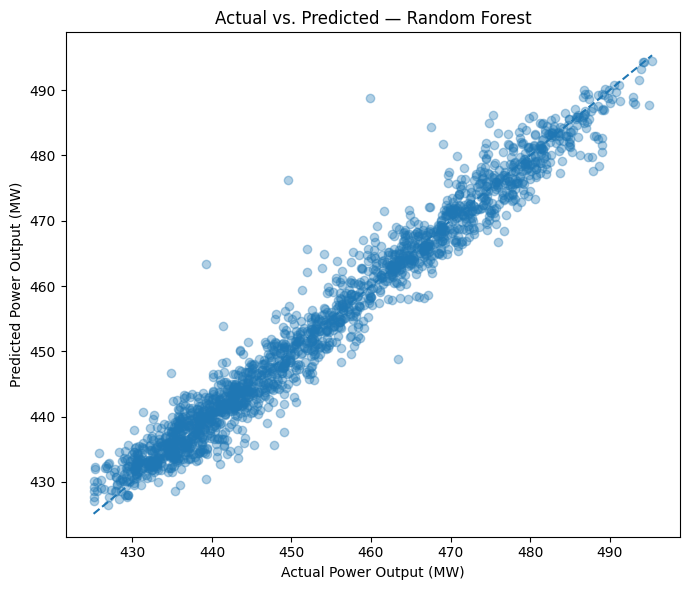

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]
best_pred = predictions[best_name]

print("Best model by RMSE:", best_name)
print(f"MAE:  {mean_absolute_error(y_test, best_pred):.3f} MW")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_pred)):.3f} MW")
print(f"R²:   {r2_score(y_test, best_pred):.4f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.35)
low = min(y_test.min(), best_pred.min())
high = max(y_test.max(), best_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Power Output (MW)")
plt.ylabel("Predicted Power Output (MW)")
plt.title(f"Actual vs. Predicted — {best_name}")
plt.tight_layout()
plt.show()

## 9. Feature importance (tree-based models)

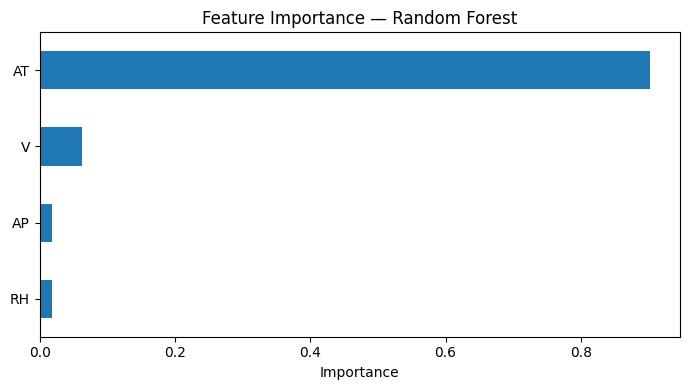

In [ ]:
if best_name in ["Random Forest", "Gradient Boosting"]:
    importances = pd.Series(
        best_model.feature_importances_, index=X.columns
    ).sort_values(ascending=True)
    importances.plot(kind="barh", figsize=(7, 4), title=f"Feature Importance — {best_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("The selected best model is Linear Regression; tree-based feature importance is not available.")

## 10. Predict power output for a new observation

In [ ]:
# Example values only. Replace these with the conditions you want to test.
new_observation = pd.DataFrame([{
    "AT": 25.0,   # Ambient temperature in °C
    "V":  50.0,   # Exhaust vacuum in cm Hg
    "AP": 1013.0, # Ambient pressure in millibar
    "RH": 60.0    # Relative humidity in %
}])

predicted_pe = best_model.predict(new_observation)[0]
print(f"Estimated net hourly electrical power output: {predicted_pe:.2f} MW")

Estimated net hourly electrical power output: 449.54 MW


## 11. Save the trained model

In [ ]:
joblib.dump(best_model, "ccpp_best_model.joblib")
print("Saved model to ccpp_best_model.joblib")

Saved model to ccpp_best_model.joblib


## Conclusion

This project trains and compares three regression algorithms to estimate net hourly electrical power output from four ambient variables. The evaluation table identifies the strongest model on the held-out test set using MAE, RMSE, and R². Record the actual scores produced by your run in your report; do not claim a specific model is best until you run the notebook on the dataset.

### Limitations
- Predictions are based on the supplied historical dataset and may not generalize to every plant or operating condition.
- The data described was collected when the plant was operating at full load.
- This is a prediction/educational project, not a replacement for plant control or safety systems.

### Dataset reference
Tüfekci, P. (2014). *Prediction of full load electrical power output of a base load operated combined cycle power plant using machine learning methods*. International Journal of Electrical Power & Energy Systems.